# **The Denoising U-Net: Training, Sampling, and Analysis**

This notebook turns the equations from notebooks 01–02 into a complete small unconditional DDPM in PyTorch. It trains a time-conditioned U-Net on 32×32 Flowers102 images, then reverses the chain to generate new images.

**Learning goals**
- Build a U-Net that mixes local image detail with multiscale context.
- Encode discrete timesteps as continuous feature vectors.
- Implement the DDPM noise-prediction training objective and ancestral sampler.
- Inspect loss behavior, denoising trajectories, sample diversity, and failure modes.

> The default run now trains for 500 epochs and uses an exponential moving average (EMA) of the network weights for sampling. With the checkpoint already produced by the earlier 150-epoch run, rerunning the notebook resumes from that checkpoint and trains for 350 more epochs. On a fresh checkout it starts from scratch. A CUDA GPU is strongly recommended; the full CPU run can take several hours. `QUICK_RUN=True` skips checkpoint resumption and only checks that the pipeline executes.


## 1. Setup and data

We use the same image normalization and Flowers102 split as notebook 01. The training objective is unconditional, so labels are discarded by the loader. `drop_last=True` keeps batch shapes consistent and makes the final smaller batch unnecessary for this demo.

In [1]:
import math, time
import copy
from pathlib import Path
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMAGE_SIZE = 32
BASE_CHANNELS = 16
transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor(), transforms.Normalize((0.5,)*3, (0.5,)*3)])
flowers = datasets.Flowers102(root='data/flowers102', split='train', download=True, transform=transform)
QUICK_RUN = False  # Set True only to check that the pipeline runs.
BATCH_SIZE = 32 if not QUICK_RUN else 8
loader = DataLoader(flowers, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=0, pin_memory=(device.type == 'cuda'))
print(f'{len(flowers)} images | {len(loader)} batches/epoch | {device}')

1020 images | 31 batches/epoch | cpu


## 2. Timestep embeddings

The U-Net must know the corruption level. We encode timestep $t$ with sinusoidal features, analogous to positional encodings: low and high frequencies give the network a smooth way to distinguish nearby and distant steps. A small MLP maps the fixed encoding to the channel dimension used by residual blocks. The encoding is deterministic; the MLP learns how each noise level should affect feature processing.

In [2]:
def sinusoidal_embedding(t, dim):
    half = dim // 2
    scale = math.log(10000) / max(half - 1, 1)
    frequencies = torch.exp(torch.arange(half, device=t.device) * -scale)
    angles = t.float()[:, None] * frequencies[None, :]
    emb = torch.cat([angles.sin(), angles.cos()], dim=1)
    if dim % 2: emb = F.pad(emb, (0, 1))
    return emb

class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(dim, dim * 4), nn.SiLU(), nn.Linear(dim * 4, dim))
    def forward(self, t):
        return self.net(sinusoidal_embedding(t, self.net[0].in_features))

## 3. U-Net building blocks

A U-Net has a contracting path and an expanding path. Downsampling grows the receptive field, allowing features to combine evidence across the image; upsampling restores spatial resolution. Skip connections copy fine-scale information around the bottleneck, which is especially useful when the prediction must preserve edges and texture.

Each residual block applies normalization, a smooth nonlinearity, and convolutions. A projected time embedding is added to the feature map. Group normalization works with small batches more reliably than batch normalization. The final 3-channel output is unconstrained because Gaussian noise is not restricted to the image range.

In [3]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, time_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(time_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class TinyUNet(nn.Module):
    def __init__(self, in_channels=3, base=32):
        super().__init__()
        self.time = TimeEmbedding(base)
        self.input = nn.Conv2d(in_channels, base, 3, padding=1)
        self.down1 = ResBlock(base, base, base)
        self.downsample1 = nn.Conv2d(base, base * 2, 4, stride=2, padding=1)
        self.down2 = ResBlock(base * 2, base * 2, base)
        self.downsample2 = nn.Conv2d(base * 2, base * 4, 4, stride=2, padding=1)
        self.mid1 = ResBlock(base * 4, base * 4, base)
        self.mid2 = ResBlock(base * 4, base * 4, base)
        self.upsample2 = nn.ConvTranspose2d(base * 4, base * 2, 4, stride=2, padding=1)
        self.up2 = ResBlock(base * 4, base * 2, base)
        self.upsample1 = nn.ConvTranspose2d(base * 2, base, 4, stride=2, padding=1)
        self.up1 = ResBlock(base * 2, base, base)
        self.out = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, in_channels, 3, padding=1))
    def forward(self, x, t):
        temb = self.time(t)
        h0 = self.input(x)
        h1 = self.down1(h0, temb)
        h2 = self.down2(self.downsample1(h1), temb)
        h = self.mid2(self.mid1(self.downsample2(h2), temb), temb)
        h = self.up2(torch.cat([self.upsample2(h), h2], dim=1), temb)
        h = self.up1(torch.cat([self.upsample1(h), h1], dim=1), temb)
        return self.out(h)

model = TinyUNet(base=BASE_CHANNELS).to(device)
parameter_count = sum(p.numel() for p in model.parameters())
print(f'Parameters: {parameter_count:,}')
with torch.no_grad():
    probe = model(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device), torch.tensor([0, 10], device=device))
print('Output shape:', tuple(probe.shape))

Parameters: 298,019
Output shape: (2, 3, 32, 32)


## 4. Schedule buffers and the training objective

For a batch, independently draw $t_i\sim\mathrm{Uniform}\{0,\ldots,T-1\}$ and $\epsilon_i\sim\mathcal N(0,I)$. Construct $x_{t_i}$ in closed form and minimize $\|\epsilon_i-\epsilon_\theta(x_{t_i},t_i)\|^2$.

Training uses zero-based array indices. We use $T=100$ here to keep the complete educational sampler manageable; increasing $T$ changes the schedule and requires retraining.

**Numerical stability for a short chain:** a raw cosine schedule reaches $\beta_{T-1}\approx1$ at its final step. In the reverse mean, this makes $1/\sqrt{\alpha_t}$ very large, so a small noise-prediction error can blow up the image. We cap the per-step variance at 0.05. The final cumulative signal remains very small (about 0.003), so the starting state is still very close to Gaussian noise, while each reverse update stays much better behaved. Always use the same capped schedule for training and sampling.

In [4]:
T = 100  # Fewer steps keep training and the educational sampler manageable.
def cosine_betas(T, s=0.008, max_beta=0.05):
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((steps / T + s) / (1 + s)) * math.pi / 2).square()
    abar = f / f[0]
    return (1 - abar[1:] / abar[:-1]).clamp(max=max_beta).float()

betas = cosine_betas(T).to(device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = F.pad(alpha_bars[:-1], (1, 0), value=1.0)
posterior_variance = betas * (1.0 - alpha_bars_prev) / (1.0 - alpha_bars)

def extract(values, t, x):
    return values.gather(0, t).view(t.shape[0], *([1] * (x.ndim - 1)))

def training_loss(model, x0):
    batch = x0.shape[0]
    t = torch.randint(0, T, (batch,), device=x0.device)
    noise = torch.randn_like(x0)
    a_bar = extract(alpha_bars, t, x0)
    xt = a_bar.sqrt() * x0 + (1.0 - a_bar).sqrt() * noise
    prediction = model(xt, t)
    return F.mse_loss(prediction, noise)

## 5. Train the denoiser

The loop below is intentionally explicit: zero gradients, evaluate the objective, backpropagate, and update parameters. Loss values are averages across pixels and examples. A falling loss indicates better noise prediction on sampled corruption levels, but it does not guarantee perceptually good images.

The default target is 500 complete passes over the 1,020-image training split (about 15,500 updates). Training resumes automatically from a compatible `checkpoints/flowers-ddpm.pt`, including the optimizer state, so the existing 150-epoch run continues instead of being discarded. Checkpoints are refreshed every 25 epochs. The EMA weights average out noisy updates and are generally more stable for image generation.


Epoch 001/500 | loss 0.87831 | 5.4s
Epoch 002/500 | loss 0.63488 | 5.2s
Epoch 003/500 | loss 0.48712 | 5.1s
Epoch 004/500 | loss 0.39560 | 5.2s
Epoch 005/500 | loss 0.32185 | 5.1s
Epoch 006/500 | loss 0.28187 | 5.3s
Epoch 007/500 | loss 0.26279 | 5.0s
Epoch 008/500 | loss 0.23897 | 5.2s
Epoch 009/500 | loss 0.21116 | 5.2s
Epoch 010/500 | loss 0.21199 | 5.0s
Epoch 011/500 | loss 0.19909 | 5.0s
Epoch 012/500 | loss 0.19882 | 5.1s
Epoch 013/500 | loss 0.19102 | 4.9s
Epoch 014/500 | loss 0.17296 | 4.9s
Epoch 015/500 | loss 0.18068 | 5.0s
Epoch 016/500 | loss 0.17654 | 5.0s
Epoch 017/500 | loss 0.16929 | 5.0s
Epoch 018/500 | loss 0.17097 | 5.1s
Epoch 019/500 | loss 0.16536 | 5.1s
Epoch 020/500 | loss 0.15975 | 5.1s
Epoch 021/500 | loss 0.15203 | 5.0s
Epoch 022/500 | loss 0.15628 | 5.0s
Epoch 023/500 | loss 0.14872 | 5.1s
Epoch 024/500 | loss 0.15822 | 5.1s
Epoch 025/500 | loss 0.16067 | 4.9s
Epoch 026/500 | loss 0.14589 | 5.4s
Epoch 027/500 | loss 0.14809 | 4.9s
Epoch 028/500 | loss 0.13427

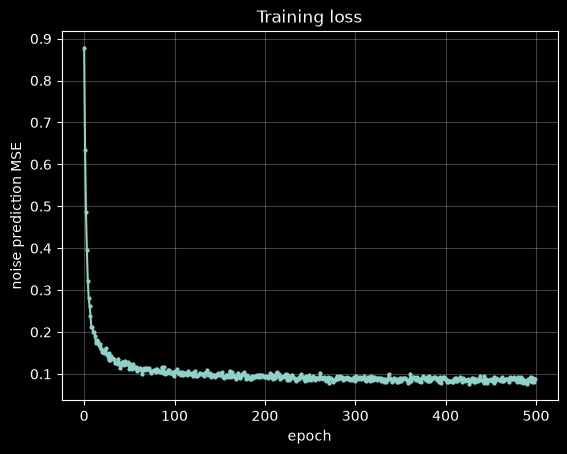

In [5]:
EPOCHS = 1 if QUICK_RUN else 500
MAX_BATCHES = 20 if QUICK_RUN else None
LEARNING_RATE = 2e-4
EMA_DECAY = 0.995
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
ema_model = copy.deepcopy(model).eval()
for parameter in ema_model.parameters():
    parameter.requires_grad_(False)

checkpoint_path = Path('checkpoints/flowers-ddpm.pt')
history = []
start_epoch = 0
if not QUICK_RUN and checkpoint_path.exists():
    saved = torch.load(checkpoint_path, map_location=device, weights_only=False)
    compatible = saved.get('T') == T and saved.get('image_size') == IMAGE_SIZE
    if compatible:
        model.load_state_dict(saved['model'])
        if 'optimizer' in saved:
            optimizer.load_state_dict(saved['optimizer'])
        history = list(saved.get('loss_history', []))
        start_epoch = len(history)
        if 'ema_model' in saved:
            ema_model.load_state_dict(saved['ema_model'])
        else:
            ema_model.load_state_dict(model.state_dict())
        print(f'Resuming compatible checkpoint at epoch {start_epoch}/{EPOCHS}.')
    else:
        print('Existing checkpoint uses different settings; starting a fresh run.')

for epoch in range(start_epoch, EPOCHS):
    model.train()
    running, seen = 0.0, 0
    start = time.time()
    for batch_index, (images, _) in enumerate(loader):
        if MAX_BATCHES is not None and batch_index >= MAX_BATCHES: break
        images = images.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = training_loss(model, images)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        with torch.no_grad():
            for ema_parameter, parameter in zip(ema_model.parameters(), model.parameters()):
                ema_parameter.mul_(EMA_DECAY).add_(parameter, alpha=1.0 - EMA_DECAY)
        running += loss.item() * images.size(0); seen += images.size(0)
    epoch_loss = running / max(seen, 1)
    history.append(epoch_loss)
    print(f'Epoch {epoch + 1:03d}/{EPOCHS} | loss {epoch_loss:.5f} | {time.time()-start:.1f}s')
    if not QUICK_RUN and (epoch + 1) % 25 == 0:
        checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({'model': model.state_dict(), 'ema_model': ema_model.state_dict(),
                    'optimizer': optimizer.state_dict(), 'T': T, 'image_size': IMAGE_SIZE,
                    'loss_history': history}, checkpoint_path)

plt.plot(history, marker='o', markersize=2); plt.xlabel('epoch'); plt.ylabel('noise prediction MSE'); plt.title('Training loss'); plt.grid(alpha=.25); plt.show()


## 6. Ancestral DDPM sampling

Using the noise prediction, the reverse mean is
$$\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right).$$
At each step, sample $x_{t-1}=\mu_\theta+\sqrt{\tilde\beta_t}z$, with $z\sim\mathcal N(0,I)$, except at $t=0$, when we add no noise. The random term preserves the probabilistic nature of the learned reverse transitions.

We keep intermediate states optionally so the denoising trajectory can be visualized. The loop makes one U-Net evaluation per timestep, which is the main inference cost of a basic DDPM.

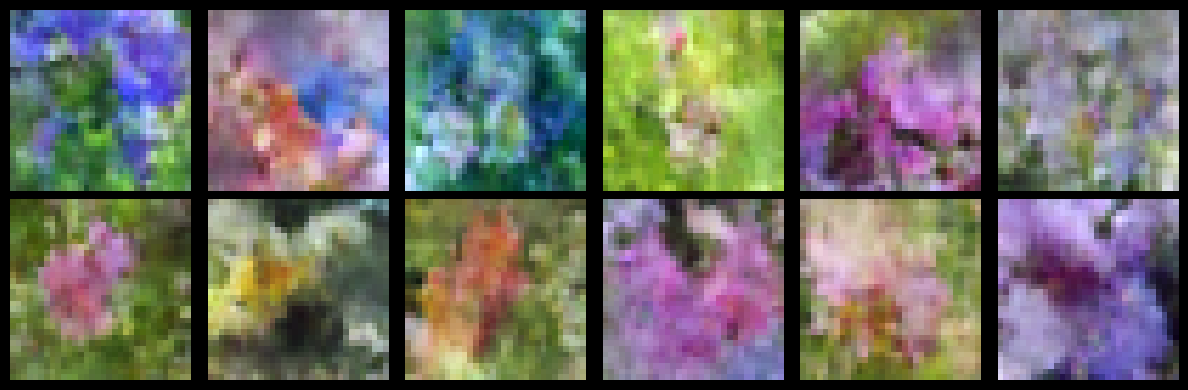

In [6]:
@torch.no_grad()
def sample_ddpm(model, n=16, keep_trajectory=False):
    model.eval()
    x = torch.randn(n, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    trajectory = {T - 1: x.detach().cpu()} if keep_trajectory else None
    for step in reversed(range(T)):
        t = torch.full((n,), step, device=device, dtype=torch.long)
        eps = model(x, t)
        beta_t = betas[step]
        alpha_t = alphas[step]
        abar_t = alpha_bars[step]
        mean = (x - beta_t / torch.sqrt(1.0 - abar_t) * eps) / torch.sqrt(alpha_t)
        if step > 0:
            x = mean + posterior_variance[step].sqrt() * torch.randn_like(x)
        else:
            x = mean
        if keep_trajectory and (step == 0 or step % max(T // 6, 1) == 0):
            trajectory[step] = x.detach().cpu()
    return x.clamp(-1, 1), trajectory

samples, trajectory = sample_ddpm(ema_model, n=12, keep_trajectory=True)
def show_grid(images, columns=6, titles=None):
    images = images.detach().cpu(); rows = math.ceil(len(images) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(2*columns, 2*rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < len(images):
            ax.imshow(((images[i].permute(1,2,0).clamp(-1,1) + 1) / 2))
            if titles: ax.set_title(str(titles[i]))
    plt.tight_layout(); return fig
show_grid(samples, columns=6); plt.show()

## 7. Analyze the denoising trajectory

A trajectory is a visual diagnostic, not just a gallery. Early reverse states should be noise-like; coarse color and composition usually emerge before fine detail. If outputs remain static noise, check that training actually updated parameters and that schedule/device tensors are consistent. If the final images collapse to near-identical colors, the model may be undertrained, too small, or using a learning rate that is poorly suited to the dataset.

The default quick run is only meant to validate tensor shapes and the end-to-end path. Do not interpret its sample quality as a limit of diffusion models.

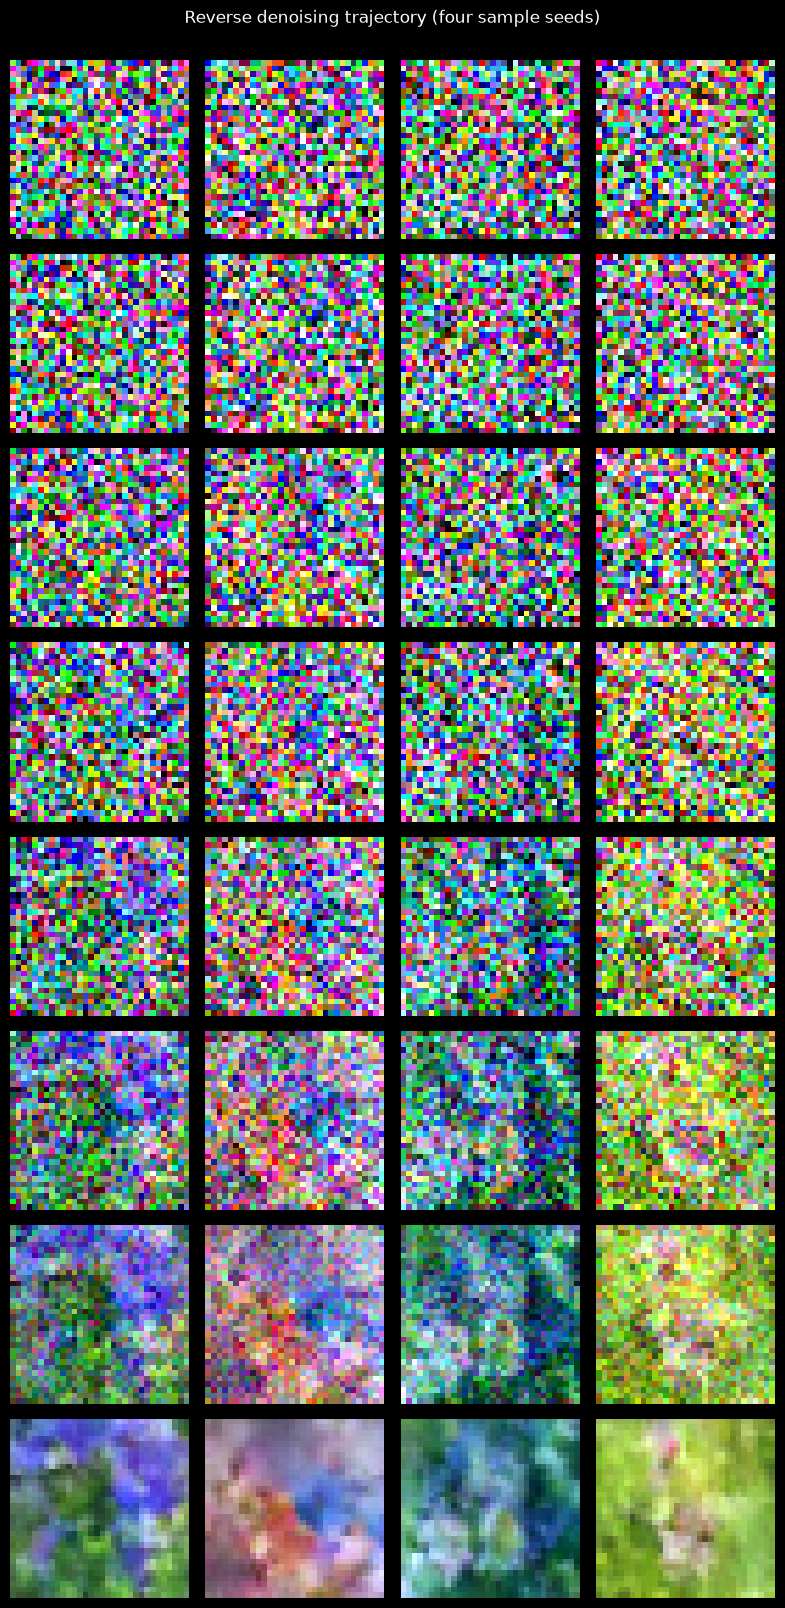

In [7]:
steps_to_show = sorted(trajectory.keys(), reverse=True)
fig, axes = plt.subplots(len(steps_to_show), 4, figsize=(8, 2*len(steps_to_show)), squeeze=False)
for row, step in enumerate(steps_to_show):
    for col in range(4):
        img = trajectory[step][col].permute(1,2,0).clamp(-1,1)
        axes[row, col].imshow((img + 1) / 2); axes[row, col].axis('off')
        if col == 0: axes[row, col].set_ylabel(f't={step}', rotation=0, labelpad=28)
plt.suptitle('Reverse denoising trajectory (four sample seeds)', y=1.002); plt.tight_layout(); plt.show()

## 8. Quantitative and qualitative diagnostics

A single scalar cannot summarize generative quality. Inspect at least:
- **Training loss:** does noise prediction improve and remain numerically stable?
- **Variety:** are samples meaningfully different, or has the model collapsed?
- **Fidelity:** do shape, color, and texture look flower-like at the target resolution?
- **Memorization:** are generated examples suspiciously close to training images?

For serious evaluation, use distributional metrics such as FID or precision/recall for generative models, computed with a suitable feature network and enough samples. Metrics can be misleading on small datasets and should complement visual inspection. The simple diversity score below is only a diagnostic: pairwise pixel distances are sensitive to alignment and do not measure semantic variety.

Mean pairwise pixel RMS distance: 0.5281
Sample tensor range: [-1.000, 1.000]


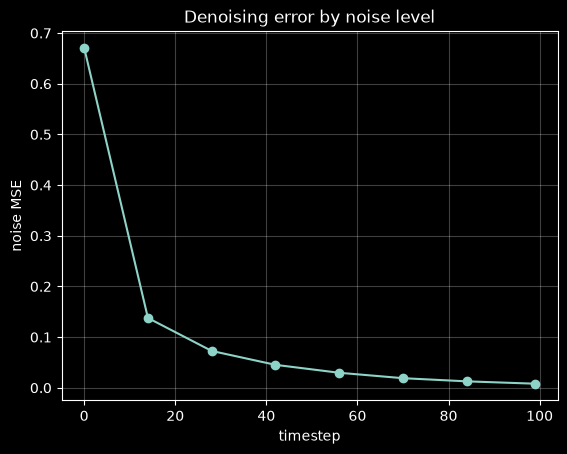

In [8]:
# A simple pixel-space diversity diagnostic (not a quality metric).
flat = samples.flatten(1)
pairwise = torch.cdist(flat, flat, p=2) / math.sqrt(flat.shape[1])
upper = pairwise[torch.triu_indices(len(samples), len(samples), offset=1).unbind()]
print(f'Mean pairwise pixel RMS distance: {upper.mean().item():.4f}')
print(f'Sample tensor range: [{samples.min().item():.3f}, {samples.max().item():.3f}]')

# Compare predicted and true injected noise on a held-out minibatch across noise levels.
model.eval()
with torch.no_grad():
    clean = torch.stack([flowers[i][0] for i in range(min(8, len(flowers)))]).to(device)
    eval_steps = torch.linspace(0, T-1, 8, device=device).long()
    per_step_mse = []
    for step in eval_steps:
        t = torch.full((len(clean),), int(step.item()), device=device, dtype=torch.long)
        eps = torch.randn_like(clean); a = extract(alpha_bars, t, clean)
        noisy = a.sqrt()*clean + (1-a).sqrt()*eps
        per_step_mse.append(F.mse_loss(model(noisy, t), eps).item())
plt.plot(eval_steps.cpu(), per_step_mse, marker='o'); plt.xlabel('timestep'); plt.ylabel('noise MSE'); plt.title('Denoising error by noise level'); plt.grid(alpha=.25); plt.show()

## 9. Common failure modes and next experiments

| Symptom | Likely causes | First checks |
|---|---|---|
| Samples look like noise | Too few updates; schedule mismatch; target or timestep bug | Confirm loss is computed against injected `noise`; compare train and sampler schedules |
| Images are gray or washed out | Undertraining; data normalization mismatch; weak capacity | Verify images are in `[-1,1]`; train longer; inspect intermediate predictions |
| Repeated near-identical samples | Underfitting or mode collapse-like behavior | Inspect pairwise samples, data variety, optimizer settings, and model capacity |
| Loss becomes NaN | Excessive learning rate, mixed-precision instability, invalid schedule values | Check `betas` in `(0,1)`, disable AMP, lower the learning rate |

Useful extensions: train longer and checkpoint; increase image size and U-Net width; add attention at low resolution; replace the simple schedule; use exponential moving averages of model weights; condition on flower labels; compare DDPM with DDIM sampling. Each extension changes a specific tradeoff—capacity, compute, fidelity, diversity, or controllability—so change one factor at a time.

In [9]:
checkpoint_path = Path('checkpoints/flowers-ddpm.pt')
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
torch.save({'model': model.state_dict(), 'ema_model': ema_model.state_dict(),
            'optimizer': optimizer.state_dict(), 'T': T, 'image_size': IMAGE_SIZE,
            'loss_history': history}, checkpoint_path)
print('Saved model and EMA checkpoint to', checkpoint_path.resolve())


Saved model and EMA checkpoint to D:\epoch-zero\generative-ai\diffusion-models\checkpoints\flowers-ddpm.pt


## 10. Full series recap

1. **Forward process:** a Gaussian Markov chain progressively erases data signal; the closed form provides arbitrary noise levels directly.
2. **Reverse process:** the model estimates the noise residual, which determines the reverse mean. The schedule defines the variance and scaling.
3. **U-Net:** multiscale convolutional features and skip connections predict a spatial noise field, while timestep embeddings tell the network the current corruption level.
4. **Training:** sample an image, a timestep, and noise; minimize predicted-noise MSE.
5. **Sampling:** begin with Gaussian noise and apply the learned reverse step repeatedly.

### Further study
- Derive the posterior coefficients by completing the square in $q(x_t\mid x_{t-1})q(x_{t-1}\mid x_0)$.
- Compare linear and cosine schedules at equal model capacity and training compute.
- Add class conditioning: embed the category label and combine it with the time embedding.
- Compare ancestral DDPM samples with fewer-step DDIM samples.
- Read a modern latent diffusion pipeline as a stack: image autoencoder, text encoder, conditioning mechanism, denoiser, and sampler.